> **Archived: rise-time study, rise time 2 s, Ts = 0.1 s.**
>
> Part of the **reference-model rise-time study** on the real M340 + ATV630 setup (September 2026). The three notebooks differ mainly in the reference-model rise time.
>
> - The fictitious reference here uses the unscaled form `r~ = y + (du + Kp*dy + Kd*d2y)/Ki`; the final notebook `algorithm/m340_dd_efrit_tuning.ipynb` scales Ki by Ts and Kd by 1/Ts.
> - Written for an older folder layout: it reads `../M340_raw_data.csv` (the initial run used for this study, no longer available) and `../M340_result_data.csv`, so it does not run as-is. Outputs are from the original run.
>
> Result run: `data/m340/rise_time_study/dd_efrit_rt2s_ts0.1s.csv`; PLC initialisation code: `plc_init/feature_matrix_rt2s_ts0.1s.txt`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import csv
import re
from sklearn.cluster import KMeans
from mpl_toolkits.mplot3d import Axes3D

In [2]:
df_raw=pd.read_csv("../M340_raw_data.csv")

rpm=df_raw["RPM"]

# Q1=rpm.quantile(0.25)
# Q3=rpm.quantile(0.75)

# IQR=Q3-Q1

# LowerBound=Q1-(1.5*IQR)
# UpperBound=Q3+(1.5*IQR)

# outliers=rpm[(rpm<LowerBound) | (rpm >UpperBound)]

df=df_raw[df_raw['RPM']<=(df_raw['SetPoint']+50)].copy()

df.info()

<class 'pandas.DataFrame'>
Index: 1200 entries, 0 to 1202
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   SetPoint     1200 non-null   float64
 1   RPM          1200 non-null   float64
 2   PWM          1200 non-null   float64
 3   Kp           1200 non-null   float64
 4   Ki           1200 non-null   float64
 5   Kd           1200 non-null   float64
 6   ScanTime_ms  1200 non-null   float64
 7   RPM_Stator   1200 non-null   float64
dtypes: float64(8)
memory usage: 84.4 KB


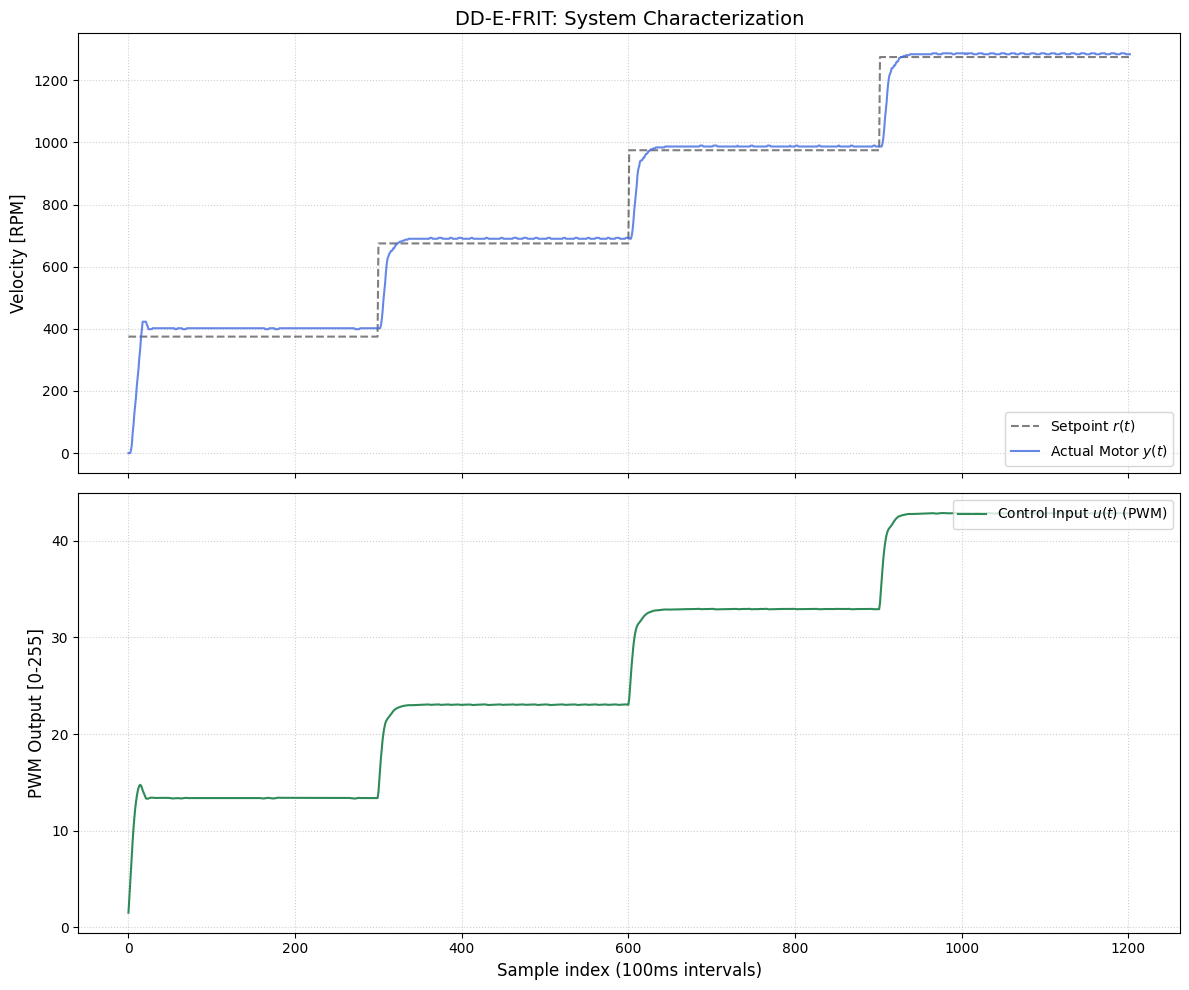

In [3]:
fig,(ax1,ax2)=plt.subplots(2,1,figsize=(12,10),sharex=True)

ax1.plot(df['SetPoint'],'k--',alpha=0.5,label='Setpoint $r(t)$')
ax1.plot(df['RPM'],'royalblue',alpha=0.8,label='Actual Motor $y(t)$')

ax1.set_title("DD-E-FRIT: System Characterization",fontsize=14)
ax1.set_ylabel("Velocity [RPM]",fontsize=12)
ax1.legend(loc='lower right')
ax1.grid(True,linestyle=':',alpha=0.6)

ax2.plot(df['PWM'],'seagreen',label='Control Input $u(t)$ (PWM)')
ax2.set_ylabel("PWM Output [0-255]",fontsize=12)
ax2.set_xlabel("Sample index (100ms intervals)",fontsize=12)
ax2.legend(loc='upper right')
ax2.grid(True,linestyle=':',alpha=0.6)

plt.tight_layout()
plt.show()

In [15]:
ny=2 #temp
nu=3 #temp
k=20
ts=0.1  
risetime=2
damping=1
max_epochs=2000
lr_kp=0.00001
lr_ki=0.00001
lr_kd=0.0000001
l=0.0009

def calculateReferenceModel (ts, risetime, damping):
    rho=ts/risetime
    mu=0.25*(1-damping)+0.51*damping
    p1=-2*np.exp(-rho/(2*mu))*np.cos(np.sqrt(4*mu-1)*rho/(2*mu))
    p2=np.exp(-rho/mu)
    P_1=1+p1+p2

    return p1, p2, P_1 

def checkDifferentials(y0, u0, i):
    dy0=y0[i]-y0[i-1]
    du0=u0[i]-u0[i-1]

    d2y=y0[i]-2*y0[i-1]+y0[i-2]

    return dy0, du0, d2y

def buildVector(i):
    return [setpoint[i+1], setpoint[i], rpm[i], rpm[i-1], pwm[i-1], pwm[i-2]]

def distanceCalc(queryPhi, infoPhi):
    total=0

    for q, d, r in zip(queryPhi, infoPhi, ranges):
        total+=abs(q-d)/r

    return total

setpoint=df["SetPoint"].values
rpm=df["RPM"].values
pwm=df["PWM"].values
kp=df["Kp"].values
ki=df["Ki"].values
kd=df["Kd"].values

ranges=[
    setpoint.max()-setpoint.min(),
    setpoint.max()-setpoint.min(),
    rpm.max()-rpm.min(),
    rpm.max()-rpm.min(),
    pwm.max()-pwm.min(),
    pwm.max()-pwm.min(),
]

optimized_kp=np.copy(kp)
optimized_ki=np.copy(ki)
optimized_kd=np.copy(kd)

p1, p2, P_1=calculateReferenceModel(ts, risetime, damping)

fs=np.sqrt(np.var(setpoint-rpm)/np.var(np.diff(pwm)))

for query_idx in range (2, len(setpoint)-1):
    distances=[]

    infoVector=buildVector(query_idx)
    
    for j in range(2, len(setpoint)-1):
        if query_idx==j:
            continue
        
        query=buildVector(j)

        d=distanceCalc(query, infoVector)
        distances.append((d,j))

    distances.sort(key=lambda x: x[0])
    neighbors=distances[:k]

    exp_values=[np.exp(-n[0]) for n in neighbors]
    total_exp=sum(exp_values)
    weights=[e/total_exp for e in exp_values]

    kp_opt=sum(weights[w]*kp[neighbors[w][1]] for w in range(k))
    ki_opt=sum(weights[w]*ki[neighbors[w][1]] for w in range(k))
    kd_opt=sum(weights[w]*kd[neighbors[w][1]] for w in range(k))

    print(f"Optimizing Row {query_idx}")
    print(f"Initial Local PID: {kp_opt:.4f}, {ki_opt:.4f}, {kd_opt:.4f}")

    r_tilda=np.zeros(len(setpoint))
    y_ref=np.zeros(len(setpoint))
    x0=np.zeros(len(setpoint))
    diff_u_tilda=np.zeros(len(setpoint))

    prev_epoch=np.inf

    for epoch in range(max_epochs):
        epoch_cost=0
        kp_grad=0
        ki_grad=0
        kd_grad=0
    

        for i in range(2, len(setpoint)):
            dy0, du0, d2y=checkDifferentials(rpm, pwm, i)

            r_tilda[i]=rpm[i]+(du0+kp_opt*dy0+kd_opt*d2y)/ki_opt
            y_ref[i]=r_tilda[i-1]*P_1-y_ref[i-1]*p1-y_ref[i-2]*p2

    
        for w_idx in range(k):
            idx=neighbors[w_idx][1]
            w=weights[w_idx]

            if idx >= len(setpoint)-1: 
                continue

            dy0, du0, d2y=checkDifferentials(rpm, pwm, idx)
            dy_ref=y_ref[idx]-y_ref[idx-1]
            d2y_ref=y_ref[idx]-2*y_ref[idx-1]+y_ref[idx-2]

            x0[idx]=du0+kp_opt*dy0+kd_opt*d2y
            diff_u_tilda[idx]=ki_opt*(r_tilda[idx]-y_ref[idx])-kp_opt*dy_ref-kd_opt*d2y_ref

            err=rpm[idx+1]-y_ref[idx+1] 

            epoch_cost+=w*0.5*((err)**2+l*fs*(diff_u_tilda[idx])**2) 

            kp_grad+=w*(-err*P_1*dy0/ki_opt+l*fs*diff_u_tilda[idx]*(dy0-dy_ref))
            ki_grad+=w*(err*P_1*x0[idx]/(ki_opt**2)+l*fs*diff_u_tilda[idx]*(rpm[idx]-y_ref[idx]))
            kd_grad+=w*(-err*P_1*d2y/ki_opt+l*fs*diff_u_tilda[idx]*(d2y-d2y_ref))
        
        kp_grad = np.clip(kp_grad, -100.0, 100.0)
        ki_grad = np.clip(ki_grad, -100.0, 100.0)
        kd_grad = np.clip(kd_grad, -20.0, 20.0)

        kp_opt=kp_opt-(lr_kp*kp_grad)
        ki_opt=ki_opt-(lr_ki*ki_grad)
        kd_opt=kd_opt-(lr_kd*kd_grad)

        if kp_opt < 0.005:
            kp_opt = 0.005
        elif kp_opt > 0.030:
            kp_opt = 0.030

        if ki_opt < 0.005:
            ki_opt = 0.005
        elif ki_opt > 0.050:
            ki_opt = 0.050

        if kd_opt < 0.0000:
            kd_opt = 0.0000
        elif kd_opt > 0.0010:
            kd_opt = 0.0010

        if epoch % 100 == 0:
            print(f"Epoch {epoch}| Cost:{epoch_cost:.6f}| PID: {kp_opt:.6f}, {ki_opt:.6f}, {kd_opt:.6f}")

        # if epoch > 30:
        #     rel_change = np.abs(prev_epoch - epoch_cost) / (np.abs(prev_epoch) + 1e-9)

        #     if rel_change < 1e-5:
        #         print(f'Converged at: {epoch}')
        #         break

        if np.abs(prev_epoch-epoch_cost) < 0.01:
                    print(f'Converged at: {epoch}')
                    break
        

        

        prev_epoch = epoch_cost
    
    optimized_kp[query_idx]=kp_opt
    optimized_ki[query_idx]=ki_opt
    optimized_kd[query_idx]=kd_opt
    print(f"Row {query_idx} Final PID: {kp_opt:.4f}, {ki_opt:.4f}, {kd_opt:.4f}")

new_dataset={
    "SetPoint": setpoint,
    "RPM": rpm,
    "PWM": pwm,
    "Kp": optimized_kp,
    "Ki": optimized_ki,
    "Kd": optimized_kd
}

optimized_df = pd.DataFrame(new_dataset)
optimized_df = optimized_df.iloc[2:-1].reset_index(drop=True)
optimized_df.to_csv("DD_E_FRIT_Optimized_Dataset.csv", index=False)

Optimizing Row 2
Initial Local PID: 0.0219, 0.0135, 0.0006
Epoch 0| Cost:16322.413893| PID: 0.022854, 0.012501, 0.000598
Epoch 100| Cost:11264.624357| PID: 0.030000, 0.005000, 0.000798
Epoch 200| Cost:11262.572615| PID: 0.030000, 0.005000, 0.000998
Converged at: 203
Row 2 Final PID: 0.0300, 0.0050, 0.0010
Optimizing Row 3
Initial Local PID: 0.0218, 0.0135, 0.0006
Epoch 0| Cost:16306.018963| PID: 0.022824, 0.012538, 0.000554
Epoch 100| Cost:11210.888525| PID: 0.030000, 0.005000, 0.000754
Epoch 200| Cost:11208.858083| PID: 0.030000, 0.005000, 0.000954
Converged at: 225
Row 3 Final PID: 0.0300, 0.0050, 0.0010
Optimizing Row 4
Initial Local PID: 0.0217, 0.0136, 0.0006
Epoch 0| Cost:16432.591539| PID: 0.022739, 0.012642, 0.000591
Epoch 100| Cost:11216.176691| PID: 0.030000, 0.005000, 0.000791
Epoch 200| Cost:11214.137881| PID: 0.030000, 0.005000, 0.000991
Converged at: 206
Row 4 Final PID: 0.0300, 0.0050, 0.0010
Optimizing Row 5
Initial Local PID: 0.0216, 0.0138, 0.0005
Epoch 0| Cost:16734.

In [16]:
def make_st():
    df=pd.read_csv("DD_E_FRIT_Optimized_Dataset.csv")
    dataset_size=len(df)

    with open("../data_init.txt", "w", newline="\n") as st_file:
        st_file.write ("IF %S21 THEN \n")
        st_file.write(f"    DATASET_SIZE := {dataset_size};\n")
        st_file.write("    (*Structure: {SetPoint, RPM, PWM} *)\n\n")

        for i, row in df.iterrows():
            st_file.write(f"    infoMatrix[{i},0] := {row['SetPoint']:.4f};\n")
            st_file.write(f"    infoMatrix[{i},1] := {row['RPM']:.4f};\n")
            st_file.write(f"    infoMatrix[{i},2] := {row['PWM']:.4f};\n")
            st_file.write(f"    pidMatrix[{i},0] := {row['Kp']:.6f};\n")
            st_file.write(f"    pidMatrix[{i},1] := {row['Ki']:.6f};\n")
            st_file.write(f"    pidMatrix[{i},2] := {row['Kd']:.6f};\n")
            st_file.write("     \n")
        
        st_file.write(f"    bDataLoaded := TRUE;\n")
        st_file.write ("END_IF;")
make_st()

In [19]:
df = pd.read_csv("DD_E_FRIT_Optimized_Dataset.csv")

sp_range = df["SetPoint"].max() - df["SetPoint"].min()
rpm_range = df["RPM"].max() - df["RPM"].min()
pwm_range = df["PWM"].max() - df["PWM"].min()

inv_sp = 1.0 / sp_range if sp_range != 0 else 1.0
inv_rpm = 1.0 / rpm_range if rpm_range != 0 else 1.0
inv_pwm = 1.0 / pwm_range if pwm_range != 0 else 1.0

print("inv_sp =", inv_sp)
print("inv_rpm =", inv_rpm)
print("inv_pwm =", inv_pwm)

features = []
pids = []

for i in range(2, len(df)):
    sp_i = df.loc[i, "SetPoint"]
    sp_prev = df.loc[i - 1, "SetPoint"]

    rpm_i = df.loc[i, "RPM"]
    rpm_prev = df.loc[i - 1, "RPM"]

    pwm_prev = df.loc[i - 1, "PWM"]
    pwm_prev2 = df.loc[i - 2, "PWM"]

    kp = df.loc[i, "Kp"]
    ki = df.loc[i, "Ki"]
    kd = df.loc[i, "Kd"]

    features.append([
        sp_i * inv_sp,
        sp_prev * inv_sp,
        rpm_i * inv_rpm,
        rpm_prev * inv_rpm,
        pwm_prev * inv_pwm,
        pwm_prev2 * inv_pwm
    ])

    pids.append([
        kp,
        ki,
        kd
    ])

feature_df = pd.DataFrame(
    features,
    columns=[
        "SP_now_norm",
        "SP_prev_norm",
        "RPM_now_norm",
        "RPM_prev_norm",
        "PWM_prev_norm",
        "PWM_prev2_norm"
    ]
)

pid_fast_df = pd.DataFrame(
    pids,
    columns=["Kp", "Ki", "Kd"]
)

feature_df.to_csv("DD_featureMatrix.csv", index=False)
pid_fast_df.to_csv("DD_pidFastMatrix.csv", index=False)

print("Original dataset size:", len(df))
print("Valid feature rows:", len(feature_df))

inv_sp = 0.0011111111111111111
inv_rpm = 0.0007936507936507937
inv_pwm = 0.02824164265190031
Original dataset size: 1194
Valid feature rows: 1192


In [20]:
def make_st_feature_matrix():
    feature_df = pd.read_csv("DD_featureMatrix.csv")
    pid_fast_df = pd.read_csv("DD_pidFastMatrix.csv")

    n = len(feature_df)

    lines = []

    lines.append("IF %S21 THEN")
    lines.append(f"    DATASET_SIZE := {n};")
    lines.append("")
    lines.append("    (* Feature structure: SP_now, SP_prev, RPM_now, RPM_prev, PWM_prev, PWM_prev2 *)")
    lines.append("")

    for i, row in feature_df.iterrows():
        lines.append(f"    featureMatrix[{i},0] := {row['SP_now_norm']:.8f};")
        lines.append(f"    featureMatrix[{i},1] := {row['SP_prev_norm']:.8f};")
        lines.append(f"    featureMatrix[{i},2] := {row['RPM_now_norm']:.8f};")
        lines.append(f"    featureMatrix[{i},3] := {row['RPM_prev_norm']:.8f};")
        lines.append(f"    featureMatrix[{i},4] := {row['PWM_prev_norm']:.8f};")
        lines.append(f"    featureMatrix[{i},5] := {row['PWM_prev2_norm']:.8f};")
        lines.append("")

        lines.append(f"    pidMatrix[{i},0] := {pid_fast_df.loc[i, 'Kp']:.8f};")
        lines.append(f"    pidMatrix[{i},1] := {pid_fast_df.loc[i, 'Ki']:.8f};")
        lines.append(f"    pidMatrix[{i},2] := {pid_fast_df.loc[i, 'Kd']:.8f};")
        lines.append("")

    lines.append("    bDataLoaded := TRUE;")
    lines.append("END_IF;")

    with open("data_init_featureMatrix.txt", "w") as f:
        f.write("\n".join(lines))

make_st_feature_matrix()

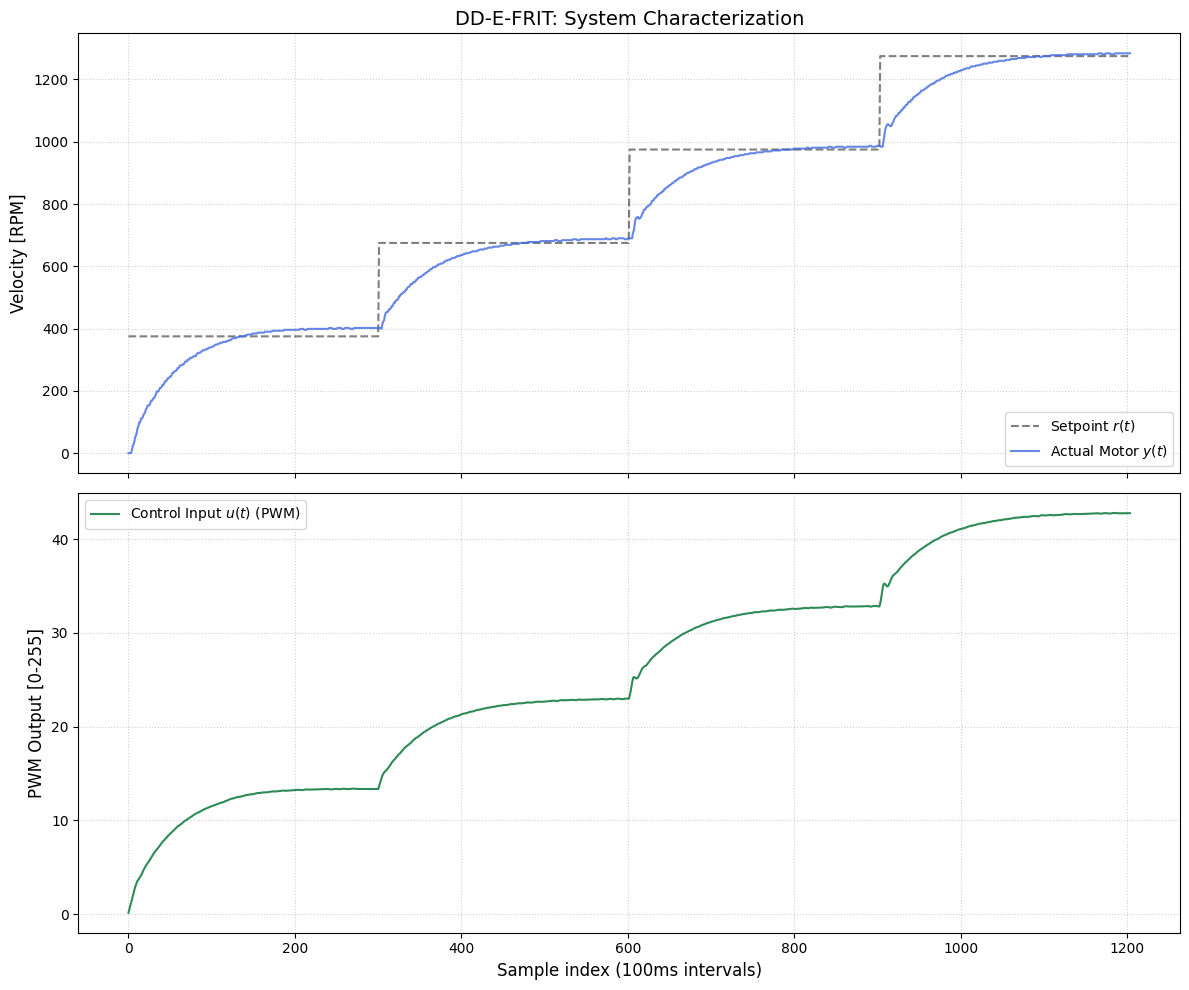

In [21]:
df2=pd.read_csv("../M340_result_data.csv")


fig,(ax1,ax2)=plt.subplots(2,1,figsize=(12,10),sharex=True)

ax1.plot(df2['SetPoint'],'k--',alpha=0.5,label='Setpoint $r(t)$')
ax1.plot(df2['RPM'],'royalblue',alpha=0.8,label='Actual Motor $y(t)$')

ax1.set_title("DD-E-FRIT: System Characterization",fontsize=14)
ax1.set_ylabel("Velocity [RPM]",fontsize=12)
ax1.legend(loc='lower right')
ax1.grid(True,linestyle=':',alpha=0.6)

ax2.plot(df2['PWM'],'seagreen',label='Control Input $u(t)$ (PWM)')
ax2.set_ylabel("PWM Output [0-255]",fontsize=12)
ax2.set_xlabel("Sample index (100ms intervals)",fontsize=12)
ax2.legend(loc='upper left')
ax2.grid(True,linestyle=':',alpha=0.6)

plt.tight_layout()
plt.show()

In [22]:
def calculate_metrics(data, name="Dataset"):
    error=data['SetPoint']-data['RPM']
    mae=np.mean(np.abs(error))                    
    rmse=np.sqrt(np.mean(error**2))
    iae=np.sum(np.abs(error))

    delta_u = np.diff(data['PWM'])                 
    tv=np.sum(np.abs(delta_u))
    delta_u_sq=np.sum(delta_u**2)     
    
    max_error = np.max(np.abs(error))
    
    return {
        "Dataset": name,
        "MAE (RPM Error)": round(mae, 3),
        "RMSE (RPM Error)": round(rmse, 3),
        "Integral Absolute Error": round(iae, 3),
        "Max Error (RPM)": round(max_error, 3),
        "Control TV (Sum |ΔPWM|)": round(tv, 3),
        "Control Effort (Sum ΔPWM^2)": round(delta_u_sq, 3)
    }

metrics = [
    calculate_metrics(df, "Initial (Static PID)"),
    calculate_metrics(df2, "Final (Optimized PID)"),
]

metrics_df = pd.DataFrame(metrics)

print("Performance Metrics Comparison")
print(metrics_df.to_string(index=False))

Performance Metrics Comparison
              Dataset  MAE (RPM Error)  RMSE (RPM Error)  Integral Absolute Error  Max Error (RPM)  Control TV (Sum |ΔPWM|)  Control Effort (Sum ΔPWM^2)
 Initial (Static PID)           23.369            45.547                27903.013            348.0                   43.486                       30.792
Final (Optimized PID)           53.243            89.909                64103.999            375.0                   46.811                        6.538


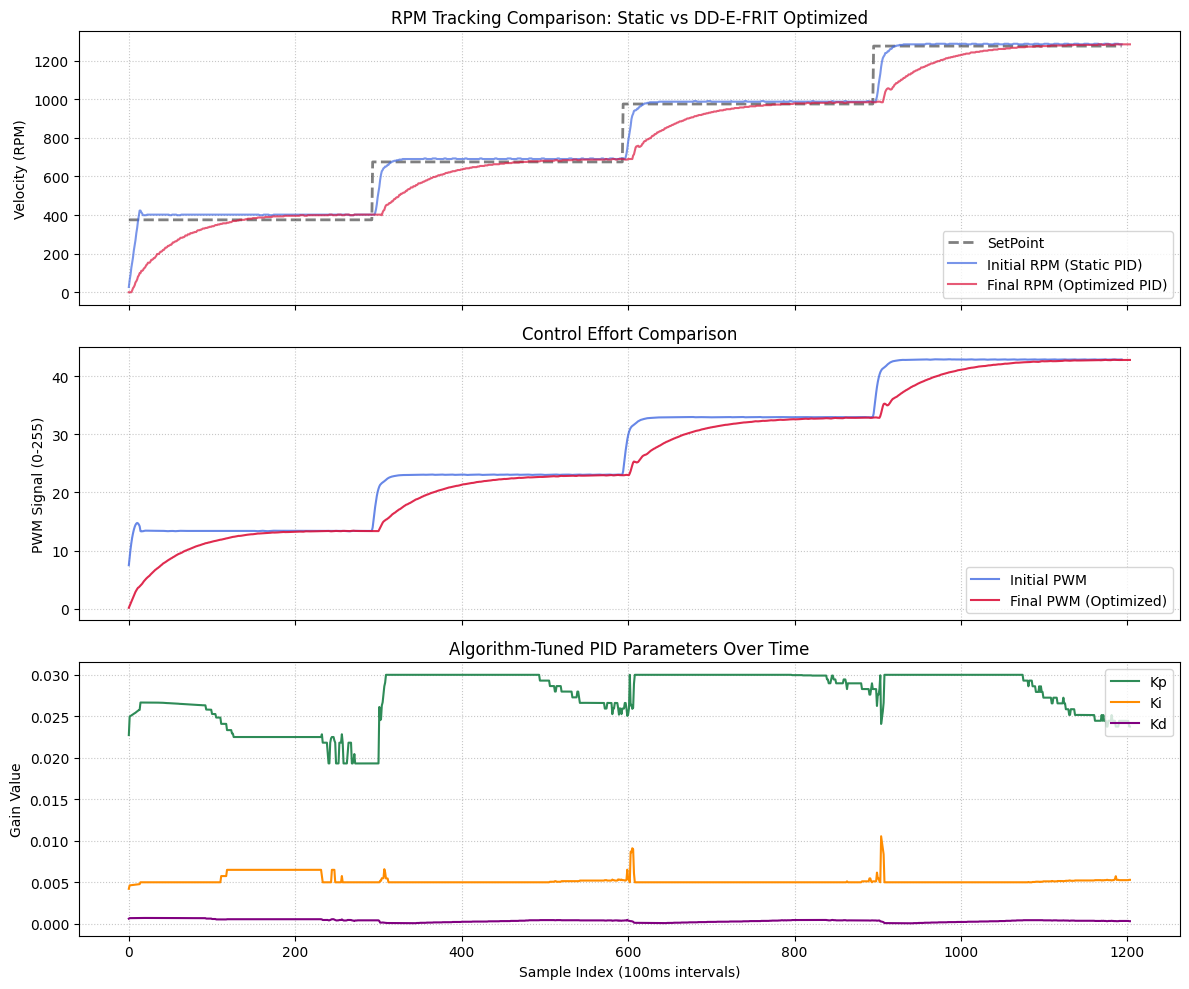

In [23]:

fig,axes= plt.subplots(3, 1, figsize=(12, 10), sharex=True)

axes[0].plot(df['SetPoint'], 'k--', alpha=0.5 , label='SetPoint', linewidth=2)
axes[0].plot(df['RPM'], label='Initial RPM (Static PID)', alpha=0.7, color='royalblue')
axes[0].plot(df2['RPM'], label='Final RPM (Optimized PID)', alpha=0.7, color='crimson')
axes[0].set_title('RPM Tracking Comparison: Static vs DD-E-FRIT Optimized', fontsize=12)
axes[0].set_ylabel('Velocity (RPM)')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle=':', alpha=0.7)

axes[1].plot(df['PWM'], label='Initial PWM', alpha=0.8, color='royalblue')
axes[1].plot(df2['PWM'], label='Final PWM (Optimized)', alpha=0.9, color='crimson')
axes[1].set_title('Control Effort Comparison', fontsize=12)
axes[1].set_ylabel('PWM Signal (0-255)')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle=':', alpha=0.7)

axes[2].plot(df2['Kp'], label='Kp', color='seagreen')
axes[2].plot(df2['Ki'], label='Ki', color='darkorange')
axes[2].plot(df2['Kd'], label='Kd', color='purple')
axes[2].set_title('Algorithm-Tuned PID Parameters Over Time', fontsize=12)
axes[2].set_xlabel('Sample Index (100ms intervals)')
axes[2].set_ylabel('Gain Value')
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

In [24]:
def calculate_metrics(data, name="Dataset"):
    error = data['SetPoint'] - data['RPM']
    mae = np.mean(np.abs(error))                    
    rmse = np.sqrt(np.mean(error**2))
    iae = np.sum(np.abs(error))
    mean_error=np.mean(error)

    delta_u = np.diff(data['PWM'])                 
    tv = np.sum(np.abs(delta_u))
    delta_u_sq = np.sum(delta_u**2) 

    error_std=np.std(error)    
    
    max_error = np.max(np.abs(error))
    
    return {
        "Dataset": name,
        "MAE (RPM Error)": round(mae, 3),
        "RMSE (RPM Error)": round(rmse, 3),
        "Integral Absolute Error": round(iae, 3),
        "Average Mean": round(mean_error, 3),
        "Max Error (RPM)": round(max_error, 3),
        "Control TV (Sum |ΔPWM|)": round(tv, 3),
        "Control Effort (Sum ΔPWM^2)": round(delta_u_sq, 3),
        "Std error": round(error_std, 3)
    }


def calculate_per_setpoint(data, name="Dataset"):
    rows = []
    
    for sp in sorted(data['SetPoint'].unique()):
        subset = data[data['SetPoint'] == sp]
        error = subset['SetPoint'] - subset['RPM']
        
        error_std = np.std(error)
        rpm_std = np.std(subset['RPM'])
        mean_err = np.mean(error)
        mae = np.mean(np.abs(error))
        
        rows.append({
            "Dataset": name,
            "Setpoint": int(sp),
            "Mean Error": round(mean_err, 2),
            "MAE": round(mae, 2),
            "Error Std": round(error_std, 2),
            "RPM Std": round(rpm_std, 2),
            "N samples": len(subset)
        })
    
    return rows

metrics = [
    calculate_metrics(df,  "Initial (Static PID)"),
    calculate_metrics(df2, "Final (Optimized PID)"),
]
metrics_df = pd.DataFrame(metrics)

print("Performance Metrics")
print(metrics_df.to_string(index=False))

per_sp_rows = []
per_sp_rows += calculate_per_setpoint(df,  "Initial (Static PID)")
per_sp_rows += calculate_per_setpoint(df2, "Final (Optimized PID)")

per_sp_df = pd.DataFrame(per_sp_rows)

print()
print(per_sp_df.to_string(index=False))

Performance Metrics
              Dataset  MAE (RPM Error)  RMSE (RPM Error)  Integral Absolute Error  Average Mean  Max Error (RPM)  Control TV (Sum |ΔPWM|)  Control Effort (Sum ΔPWM^2)  Std error
 Initial (Static PID)           23.369            45.547                27903.013        -6.686            348.0                   43.486                       30.792     45.053
Final (Optimized PID)           53.243            89.909                64103.999        43.395            375.0                   46.811                        6.538     78.743

              Dataset  Setpoint  Mean Error   MAE  Error Std  RPM Std  N samples
 Initial (Static PID)       375      -18.53 33.03      45.74    45.74        293
 Initial (Static PID)       675       -6.12 22.35      42.89    42.89        301
 Initial (Static PID)       975       -2.18 19.86      44.46    44.46        301
 Initial (Static PID)      1275       -0.18 18.46      44.86    44.86        299
Final (Optimized PID)       375       41